### 1. Tugas Pendahuluan
1.1 Persiapan dan Perkenalan Lingkungan

    1. Membuat environment baru $ python -m venv myenv

    2. Mematikan paket virtual environment yang lain
    
    3. Install dependensi paket paket:
        neo4j>=4.0,<4.3
        imdbpy==2020.9.25
        nose==1.3.7
        cinemagoerng>=0.4
        imdbinfo>=0.5
        imdbpy>=2020.9.25
        neo4j==4.2.1

1.2 Penggunaan Driver Neo4J

Mendefinisikan string koneksi ke database Neo4J

In [1]:
from getpass import getpass
from neo4j import GraphDatabase, RoutingControl

URI = "neo4j://localhost:7687"

password = getpass("Masukkan password Neo4j: ")
AUTH = ("neo4j", password)

driver = GraphDatabase.driver(URI, auth=AUTH)

driver.verify_connectivity()
print("Berhasil terhubung ke database Neo4j")

Berhasil terhubung ke database Neo4j


Melakukan pembuatan sebuah node dengan relationship nya

In [2]:
def add_friend(driver, name, friend_name):
    driver.execute_query(
    "MERGE (a:Person {name: $name}) "
    "MERGE (friend:Person {name: $friend_name}) "
    "MERGE (a)-[:KNOWS]->(friend)",
    name=name, friend_name=friend_name, database_= "neo4j",
    )

Mencetak dan menjalankan keseluruhan

In [3]:
def print_friends(driver, name):
    records, _, _= driver.execute_query(
    "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
    "RETURN friend.name ORDER BY friend.name",
    name=name, database_= "neo4j", routing_= RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

with GraphDatabase.driver (URI, auth=AUTH, ) as driver:
    add_friend(driver, "Arthur", "Guinevere")
    add_friend(driver, "Arthur", "Lancelot")
    add_friend(driver, "Arthur", "Merlin")
    print_friends(driver, "Arthur")


Guinevere
Lancelot
Merlin


# Pertanyaan Pendahuluan
1. Apa nama database yang digunakan pada tutorial ini?
Database yang digunakan pada tutorial ini adalah Neo4J
2. Sebutkan akses lain (seperti sintaks DDL/DML CYPHER) yang dapat digunakan mengakses database dalam 1 instance! Akses ke database lain dalam satu instance Neo4j dapat dilakukan secara langsung di dalam kode Python melalui pembuatan sesi driver.session(database="nama_db") atau penyisipan klausa Cypher USE <nama_db> di awal string kueri.
3. Apa jenis graf pertemanan yang telah dibuat disitu?
Jenis graf pertemanan yang dibuat adalah graf berarah karena relasi :KNOWS memeiliki arah panah yang jelas dari entitas asal yaitu Arthur menuju entitas tujuan yaitu Guinevere, Lancelot, dan Merlin

### 1.3 Melakukan proses Impor Data dari RetailRocket ke Database Neo4J

### 1. Unduh data dari kaggle
curl.exe -L -o ecommerce-dataset.zip

### 2. Memeriksa fitur yang telah diunduh

In [6]:
import pandas as pd

df_sample = pd.read_csv("data/events.csv", nrows=5)

print(df_sample.shape)
print(df_sample.columns)
print(df_sample.dtypes)
print(df_sample.head(1))

(5, 5)
Index(['timestamp', 'visitorid', 'event', 'itemid', 'transactionid'], dtype='object')
timestamp          int64
visitorid          int64
event             object
itemid             int64
transactionid    float64
dtype: object
       timestamp  visitorid event  itemid  transactionid
0  1433221332117     257597  view  355908            NaN


### 3. Impor pustaka dan konfigurasi dasar

In [32]:
import os
import sys
import pandas as pd
from neo4j import GraphDatabase
from tqdm import tqdm
from getpass import getpass

URI = "neo4j://localhost:7687"
USER = "neo4j"
PASSWORD = getpass("Masukkan password Neo4j: ")
DATABASE = "grafuts"
SOURCE_DIR = "data_filtered"
BATCH_SIZE = 10000
csv_file_path = os.path.join(SOURCE_DIR, "events_P1_train.csv")
print("Path:", csv_file_path)

Path: data_filtered\events_P1_train.csv


### 4. Membuat fungsi constraint

In [33]:
def create_constraints(session):
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE")
    session.run("CREATE CONSTRAINT IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE")

### 5. fungsi impor batch

In [34]:
def import_batch(tx, batch):
    cypher_query = """
    UNWIND $batch AS row
    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})
    WITH v, i, row
    CALL {
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'view'
        CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'addtocart'
        CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i)
        UNION ALL
        WITH v, i, row
        WITH v, i, row WHERE row.event = 'transaction'
        CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i)
    }
    """
    tx.run(cypher_query, batch=batch)

### 6. Cek file dan koneksi

In [36]:
if not os.path.exists(csv_file_path):
    raise FileNotFoundError(f"File '{csv_file_path}' tidak ditemukan!")

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
driver.verify_connectivity()
print(f"Berhasil terhubung ke Neo4j server ({URI})")

Berhasil terhubung ke Neo4j server (neo4j://localhost:7687)


### 7. Menghitung total baris

In [37]:
with open(csv_file_path, "r", encoding="utf-8") as f:
    total_rows = sum(1 for _ in f) - 1

total_chunks = (total_rows // BATCH_SIZE) + 1
print(f"Total baris: {total_rows:,} | Perkiraan batch: {total_chunks}")

Total baris: 630,821 | Perkiraan batch: 64


### 8 Membuat constraint

In [38]:
with driver.session(database=DATABASE) as session:
    create_constraints(session)
print(f"Constraint dibuat pada database '{DATABASE}'")

Constraint dibuat pada database 'grafuts'


### 9. Eksekusi impor data

In [39]:
with driver.session(database=DATABASE) as session:
    print(f"Membuat constraint/indeks pada database {DATABASE}...")
    create_constraints(session)
    
    print(f"Membaca file data dari: {csv_file_path}")
    chunks = pd.read_csv(csv_file_path, chunksize=BATCH_SIZE)

    print(f"Memulai proses impor data ke database {DATABASE}...")
    for chunk in tqdm(chunks, total=total_chunks, desc="Mengimpor Batch Data"):
        chunk["transactionid"] = (
            chunk["transactionid"].fillna("").astype(str)
        )
        records = chunk.to_dict(orient="records")
        session.execute_write(import_batch, records)

driver.close()
print("Proses impor berhasil.")

Membuat constraint/indeks pada database grafuts...
Membaca file data dari: data_filtered\events_P1_train.csv
Memulai proses impor data ke database grafuts...


Mengimpor Batch Data: 100%|██████████| 64/64 [04:47<00:00,  4.49s/it]

Proses impor berhasil.


### Inisialisasi Environment dan Koneksi Database Neo4j

Sel ini bertindak sebagai tahap persiapan environment kerja dan pembentukan koneksi aman ke database graph Neo4j utsGraf.

#### Library yang Digunakan:
* pandas dan numpy: Digunakan untuk pemrosesan, manipulasi, dan analisis data berstruktur matriks atau tabel.
* scipy.sparse (csr_matrix): Digunakan untuk menyimpan dan mengelola matriks VSM berkepadatan rendah secara efisien di memori.
* sklearn.metrics.pairwise (cosine_similarity): Digunakan untuk menghitung nilai kemiripan sudut antar vektor item.
* networkx dan matplotlib.pyplot: Digunakan untuk mengonstruksi, memodelkan, dan memvisualisasikan struktur graf.
* neo4j.GraphDatabase: Driver resmi Python untuk mengeksekusi kueri Cypher SQL dan berinteraksi dengan database Neo4j.
* getpass: Menyediakan input password secara tersembunyi untuk menjaga keamanan kredensial database.
* os, random, math, dan collections (defaultdict): Digunakan untuk mendukung fungsi utilitas sistem, operasi matematika, pengacakan data, serta pengelolaan struktur data dictionary bawaan Python.
* matplotlib.lines (Line2D): Digunakan untuk membuat dan mengustomisasi elemen garis atau kustom legenda pada plot visualisasi.

In [51]:
import getpass
import os
import random
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import math
from collections import defaultdict
from matplotlib.lines import Line2D
from neo4j import GraphDatabase
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

URI = "neo4j://localhost:7687"
USER = "neo4j"
DATABASE = "grafuts"

PASSWORD = getpass.getpass("Masukkan Password Neo4j: ")

driver = GraphDatabase.driver(URI, auth=(USER, PASSWORD))
print("Driver Neo4j siap.")

Driver Neo4j siap.


# 2. Pengerjaan UTS

### 2.1 Wrangling dan EDA

### 1 dan 2 Pemfilteran Data Berdasarkan Rentang Waktu (Train dan Test Split)

Sel ini berfungsi untuk membagi data mentah events.csv menjadi dua himpunan data terpisah, yaitu data train (P1) dan data test (P2).

#### Langkah-Langkah Pemrosesan:
1. Penentuan Rentang Waktu: Mengonversi string tanggal Periode 1 (11 Juni - 11 Juli 2015) dan Periode 2 (11 Agustus - 21 Agustus 2015) menjadi nilai timestamp Unix berpresisi milidetik berbasis zona waktu UTC.
2.  Pemuatan dan Pemfilteran Data: Membaca dataset mentah dari data/events.csv dan memfilter baris data yang berada di dalam rentang timestamp P1 dan P2.
3. Penyimpanan Dataset: Membuat direktori data_filtered dan menyimpan hasil filter ke dalam berkas CSV terpisah (events_P1_train.csv untuk training dan events_P2_test.csv untuk testing).

In [75]:
p1_start_str = "2015-06-11 00:00:00"
p1_end_str   = "2015-07-11 23:59:59"

p2_start_str = "2015-08-11 00:00:00"
p2_end_str   = "2015-08-21 23:59:59"

ts_p1_start = int(pd.Timestamp(p1_start_str, tz='UTC').timestamp() * 1000)
ts_p1_end   = int(pd.Timestamp(p1_end_str, tz='UTC').timestamp() * 1000)

ts_p2_start = int(pd.Timestamp(p2_start_str, tz='UTC').timestamp() * 1000)
ts_p2_end   = int(pd.Timestamp(p2_end_str, tz='UTC').timestamp() * 1000)

print("HASIL KONVERSI TIMESTAMP")
print(f"P1: {p1_start_str} ({ts_p1_start}) s.d {p1_end_str} ({ts_p1_end})")
print(f"P2: {p2_start_str} ({ts_p2_start}) s.d {p2_end_str} ({ts_p2_end})\n")

df_raw = pd.read_csv("data/events.csv")

df_p1 = df_raw[(df_raw['timestamp'] >= ts_p1_start) & (df_raw['timestamp'] <= ts_p1_end)]
df_p2 = df_raw[(df_raw['timestamp'] >= ts_p2_start) & (df_raw['timestamp'] <= ts_p2_end)]

os.makedirs("data_filtered", exist_ok=True)
df_p1.to_csv("data_filtered/events_P1_train.csv", index=False)
df_p2.to_csv("data_filtered/events_P2_test.csv", index=False)

print("HASIL PEMFILTERAN")
print(f"P1 (Training): {len(df_p1):,} baris -> Disimpan ke 'data_filtered/events_P1_train.csv'")
print(f"P2 (Testing) : {len(df_p2):,} baris -> Disimpan ke 'data_filtered/events_P2_test.csv'")

HASIL KONVERSI TIMESTAMP
P1: 2015-06-11 00:00:00 (1433980800000) s.d 2015-07-11 23:59:59 (1436659199000)
P2: 2015-08-11 00:00:00 (1439251200000) s.d 2015-08-21 23:59:59 (1440201599000)

HASIL PEMFILTERAN
P1 (Training): 630,821 baris -> Disimpan ke 'data_filtered/events_P1_train.csv'
P2 (Testing) : 201,000 baris -> Disimpan ke 'data_filtered/events_P2_test.csv'


### 3 Analisis Komposisi Simpul dan Relasi pada Graf

Sel ini digunakan untuk mengecek total jumlah simpul (node) dan relasi yang tersimpan di dalam database Neo4j.

#### Langkah-Langkah Pemrosesan:
1. Kueri Komposisi Simpul: Menggunakan MATCH (n) untuk mengelompokkan simpul berdasarkan label pertamanya dan menghitung total simpul untuk setiap label.
2. Kueri Komposisi Relasi: Menggunakan MATCH ()-[r]->() untuk mengelompokkan relasi berdasarkan tipe relasinya dan menghitung total relasi yang terbentuk.
3. Pembentukan dan Penampilan DataFrame: Memproses hasil kueri menjadi dua tabel DataFrame terpisah (df_nodes dan df_rels) lalu menampilkannya langsung di notebook.

In [46]:
def get_subgraph_composition(driver, db_name):
    query_nodes = """
    MATCH (n) 
    RETURN labels(n)[0] AS node_type, count(n) AS total_nodes
    """
    query_rels = """
    MATCH ()-[r]->() 
    RETURN type(r) AS rel_type, count(r) AS total_rels
    """
    
    with driver.session(database=db_name) as session:
        nodes_res = session.run(query_nodes).data()
        rels_res = session.run(query_rels).data()
        
    print("KOMPOSISI SIMPUL")
    df_nodes = pd.DataFrame(nodes_res)
    display(df_nodes)
    
    print("\nKOMPOSISI RELASI")
    df_rels = pd.DataFrame(rels_res)
    display(df_rels)

get_subgraph_composition(driver, DATABASE)

KOMPOSISI SIMPUL


,node_type,total_nodes
0,Visitor,326311
1,Item,120903



KOMPOSISI RELASI


,rel_type,total_rels
0,VIEWED,609576
1,ADDED_TO_CART,15975
2,BOUGHT,5270


### Ekstraksi Data dan Pembentukan Matriks VSM (Vector Space Model)

Sel ini mengambil data interaksi antara visitor dan item dari database Neo4j, lalu mengolahnya menjadi matriks VSM berkepadatan rendah (sparse matrix) untuk User dan Item.

#### Langkah-Langkah Pemrosesan:
1. Pengambilan Data Interaksi: Menjalankan kueri Cypher untuk menghitung total frekuensi interaksi antara setiap visitor (user_id) dan produk (item_id).
2. Pengodean Indeks Matriks: Mengubah ID user dan ID item menjadi angka indeks berbasis posisi (row_ind dan col_ind) agar dapat dipetakan ke koordinat matriks.
3. Pembentukan VSM User: Membuat matriks sparse_vsm_user (User x Item) di mana nilai tiap sel berisi jumlah frekuensi interaksi.
4. Pembentukan VSM Item: Memutar (transpose) matriks VSM User menjadi sparse_vsm_item (Item x User) untuk kebutuhan analisis kemiripan antar-item.

In [47]:
query_vsm = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS user_id, i.itemId AS item_id, count(r) AS interaction_count
"""

with driver.session(database=DATABASE) as session:
    data_ui = session.run(query_vsm).data()
driver.close()

df_ui = pd.DataFrame(data_ui)

user_cats = pd.Categorical(df_ui["user_id"])
item_cats = pd.Categorical(df_ui["item_id"])

row_ind = user_cats.codes
col_ind = item_cats.codes

sparse_vsm_user = csr_matrix((df_ui["interaction_count"], (row_ind, col_ind)))
sparse_vsm_item = sparse_vsm_user.T.tocsr()

print(f"VSM User terbentuk dengan shape: {sparse_vsm_user.shape}")
print(f"VSM Item terbentuk dengan shape: {sparse_vsm_item.shape}")

VSM User terbentuk dengan shape: (326311, 120903)
VSM Item terbentuk dengan shape: (120903, 326311)


### 4. Analisis Karakteristik VSM User dan Visualisasi Jaringan Pengguna

Sel ini digunakan untuk mengukur karakteristik pada matriks VSM User sekaligus memvisualisasikan hubungan antarpengguna teraktif.

#### Langkah-Langkah Pemrosesan:
1. Perhitungan Metrik VSM: Menhitung total baris (user), total kolom (item), persentase kekosongan data (sparsity), serta rata-rata jumlah item yang pernah dikunjungi oleh satu pengguna.
2. Pemilihan Sampel Pengguna Teraktif: Mengambil 50 pengguna yang memiliki jumlah interaksi terbanyak untuk memfokuskan analisis jaringan.
3. Pembentukan Matriks Hubungan Pengguna: Mengalikan matriks sampel pengguna untuk menghitung seberapa banyak produk yang sama-sama pernah dikunjungi oleh dua pengguna berbeda (kesamaan interaksi).
4. Visualisasi Jaringan Pengguna: Menggambar graf proyeksi homogen yang memperlihatkan bagaimana 50 pengguna teraktif saling terhubung satu sama lain.

KARAKTERISTIK MATRIKS VSM USER
Shape Matriks (Baris x Kolom) : (326,311, 120,903)
Jumlah User (Baris)           : 326,311 user
Jumlah Fitur Item (Kolom)     : 120,903 item
Sparsity (Kekosongan Data)    : 99.998760%
Rata-rata Item per User       : 1.50 item


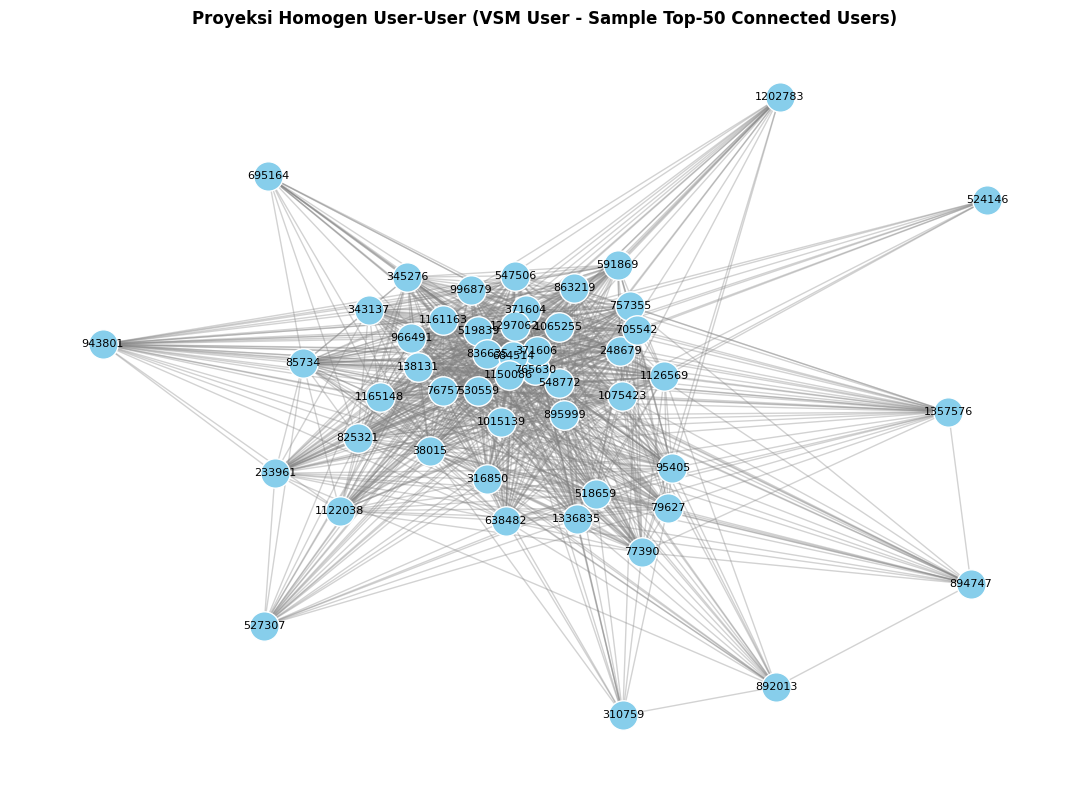

In [48]:
num_users, num_items = sparse_vsm_user.shape
total_cells = num_users * num_items
non_zero = sparse_vsm_user.nnz
sparsity = ((total_cells - non_zero) / total_cells) * 100

items_per_user = np.array((sparse_vsm_user > 0).sum(axis=1)).flatten()
avg_items_per_user = np.mean(items_per_user)

print("KARAKTERISTIK MATRIKS VSM USER")
print(f"Shape Matriks (Baris x Kolom) : ({num_users:,}, {num_items:,})")
print(f"Jumlah User (Baris)           : {num_users:,} user")
print(f"Jumlah Fitur Item (Kolom)     : {num_items:,} item")
print(f"Sparsity (Kekosongan Data)    : {sparsity:.6f}%")
print(f"Rata-rata Item per User       : {avg_items_per_user:.2f} item")

top_50_user_idx = np.argsort(items_per_user)[-50:]
sparse_sub_user = sparse_vsm_user[top_50_user_idx, :]

user_adj_matrix = sparse_sub_user.dot(sparse_sub_user.T).toarray()
np.fill_diagonal(user_adj_matrix, 0)

top_50_user_ids = user_cats.categories[top_50_user_idx]
df_user_adj = pd.DataFrame(
    user_adj_matrix, index=top_50_user_ids, columns=top_50_user_ids
)

G_user = nx.from_pandas_adjacency(df_user_adj)

plt.figure(figsize=(11, 8))
pos_user = nx.spring_layout(G_user, k=0.55, seed=42)

nx.draw_networkx_nodes(
    G_user, pos_user, node_color="#87CEEB", node_size=450, edgecolors="white"
)
nx.draw_networkx_labels(G_user, pos_user, font_size=8, font_family="sans-serif")
nx.draw_networkx_edges(G_user, pos_user, edge_color="gray", alpha=0.35)

plt.title(
    "Proyeksi Homogen User-User (VSM User - Sample Top-50 Connected Users)",
    fontsize=12,
    fontweight="bold",
)
plt.axis("off")
plt.tight_layout()
plt.show()

### 5. Analisis Karakteristik VSM Item dan Visualisasi Jaringan Produk

Sel ini digunakan untuk mengukur karakteristik pada matriks VSM Item sekaligus memvisualisasikan keterhubungan antarproduk terpopuler.

#### Langkah-Langkah Pemrosesan:
1. Perhitungan Metrik VSM Item: Menghitung total jumlah item, total user, persentase kekosongan data (sparsity), serta rata-rata pengunjung per item.
2. Pemilihan Sampel Produk Terpopuler: Mengambil 50 item dengan jumlah pengunjung atau interaksi terbanyak.
3. Pembentukan Matriks Hubungan Produk: Mengalikan matriks item untuk menghitung frekuensi dua produk dikunjungi oleh pengunjung yang sama.
4. Visualisasi Jaringan Produk: Menggambar graf proyeksi homogen yang menampilkan keterhubungan antar-50 produk terpopuler serta menghapus simpul yang tidak memiliki tetangga (isolated nodes).

KARAKTERISTIK MATRIKS VSM ITEM
Shape Matriks (Baris x Kolom) : (120,903, 326,311)
Jumlah Item (Baris)           : 120,903 item
Jumlah Fitur User (Kolom)     : 326,311 user
Sparsity (Kekosongan Data)    : 99.998760%
Rata-rata User per Item       : 4.05 user


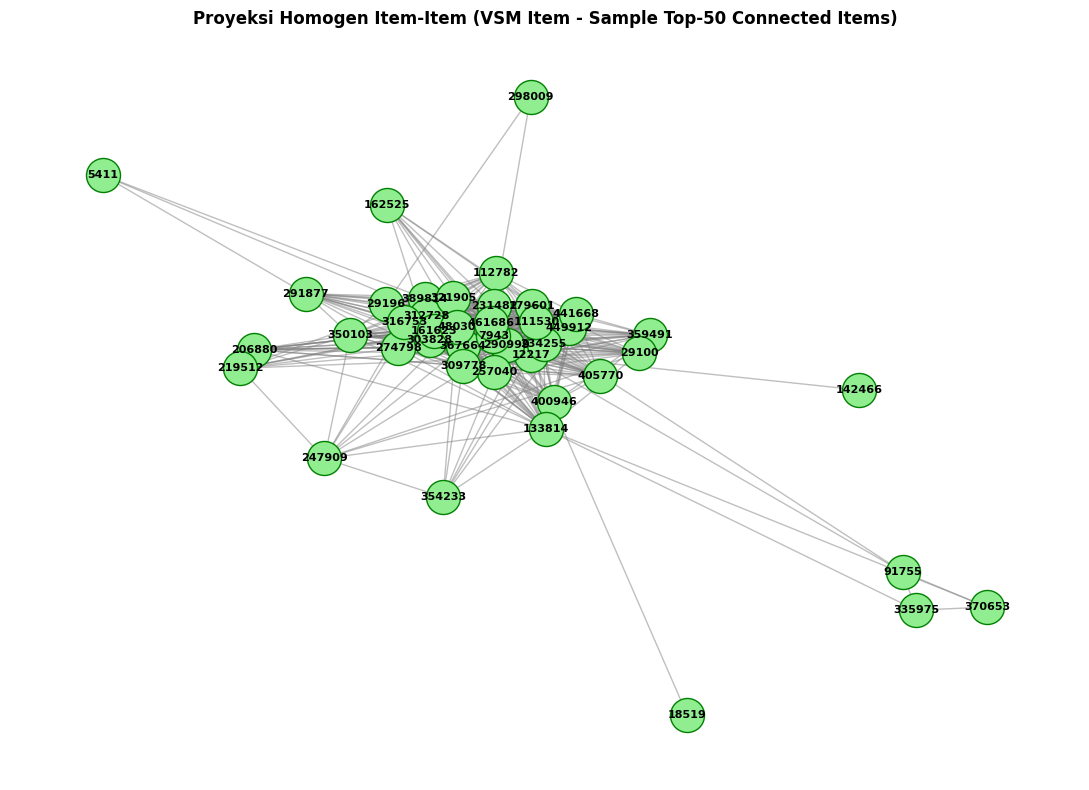

In [49]:
num_items, num_users = sparse_vsm_item.shape
total_cells = num_items * num_users
non_zero = sparse_vsm_item.nnz
sparsity = ((total_cells - non_zero) / total_cells) * 100

users_per_item = np.array((sparse_vsm_item > 0).sum(axis=1)).flatten()
avg_users_per_item = np.mean(users_per_item)

print("KARAKTERISTIK MATRIKS VSM ITEM")
print(f"Shape Matriks (Baris x Kolom) : ({num_items:,}, {num_users:,})")
print(f"Jumlah Item (Baris)           : {num_items:,} item")
print(f"Jumlah Fitur User (Kolom)     : {num_users:,} user")
print(f"Sparsity (Kekosongan Data)    : {sparsity:.6f}%")
print(f"Rata-rata User per Item       : {avg_users_per_item:.2f} user")

top_50_item_idx = np.argsort(users_per_item)[-50:]
sparse_sub_item = sparse_vsm_item[top_50_item_idx, :]

item_adj_matrix = sparse_sub_item.dot(sparse_sub_item.T).toarray()
np.fill_diagonal(item_adj_matrix, 0)

top_50_item_ids = item_cats.categories[top_50_item_idx]
df_item_adj = pd.DataFrame(
    item_adj_matrix, index=top_50_item_ids, columns=top_50_item_ids
)

G_item = nx.from_pandas_adjacency(df_item_adj)
G_item.remove_nodes_from(list(nx.isolates(G_item))) 

plt.figure(figsize=(11, 8))
pos_item = nx.spring_layout(G_item, k=0.8, seed=42)

nx.draw_networkx_nodes(
    G_item, pos_item, node_color="lightgreen", node_size=600, edgecolors="green"
)
nx.draw_networkx_labels(G_item, pos_item, font_size=8, font_weight="bold")
nx.draw_networkx_edges(G_item, pos_item, edge_color="gray", alpha=0.5)

plt.title(
    "Proyeksi Homogen Item-Item (VSM Item - Sample Top-50 Connected Items)",
    fontsize=12,
    fontweight="bold",
)
plt.axis("off")
plt.tight_layout()
plt.show()

### 6. Perbandingan proyeksi yang lebih baik
Proyeksi item-Item (VSM Item) jauh lebih efektif dan efisien dibandingkan user-user (VSM User). Dari segi dimensi, matriks proyeksi Item-Item memiliki nilai lebih kecil dibandingkan matriks user-user, sehingga komputasinya jauh lebih cepat dan hemat RAM. Meskipun tingkat sparsity keduanya memiliki nilai yang sama, namun ada perbedaan pada karakteristik lain. Rata-rata User per Item mencapai 4,05 user, sedangkan rata-rata Item per user hanya 1,50 item. Sinyal data yang 2,7 kali lipat lebih tebal ini membuat vektor produk lebih stabil dan kebal dari masalah cold-start. Pada Plot NetworkX, proyeksi Item-Item berhasil membentuk klaster komunitas produk yang padat di pusat, sedangkan proyeksi User-User cenderung menyebar dan terisolasi akibat tipisnya riwayat interaksi pengguna.


### 7a. Menghitung Cosine Similarity untuk Item Terpopuler

Sel ini mencari satu produk yang paling banyak interaksi, lalu menghitung tingkat kemiripan produk tersebut dengan produk-produk lainnya berdasarkan pengunjung yang sama.

#### Langkah-Langkah Pemrosesan:
1. Pencarian Item Terpopuler: Mengambil satu item acuan yang memiliki jumlah interaksi terbanyak di dalam database.
2. Pencarian Pengunjung Bersama: Mencari item lain yang pernah dikunjungi oleh pengunjung yang sama dengan item acuan (shared visitors).
3. Perhitungan Cosine Similarity: Menghitung skor kemiripan antara item acuan dan item lainnya menggunakan rumus Cosine Similarity, lalu mengurutkannya untuk mengambil 5 item teratas.
4. Eksekusi Kueri: Menjalankan kueri Cypher di Neo4j dan menyimpan hasilnya ke dalam tabel DataFrame.

In [52]:
query_pasangan = """
MATCH (v:Visitor)-[r]->(i:Item)
RETURN v.visitorId AS visitor, i.itemId AS item, count(r) AS n
"""
with driver.session(database=DATABASE) as session:
    df = pd.DataFrame(session.run(query_pasangan).data())

stat = df.groupby("item").agg(total_interaksi=("n", "sum"),
                              jumlah_visitor=("visitor", "nunique"))

item_acuan = stat["total_interaksi"].idxmax()
target_users = stat.loc[item_acuan, "jumlah_visitor"]
total_interaksi = stat.loc[item_acuan, "total_interaksi"]

visitor_target = df.loc[df["item"] == item_acuan, "visitor"].unique()
lain = df[df["visitor"].isin(visitor_target) & (df["item"] != item_acuan)]

hasil = (lain.groupby("item")["visitor"].nunique()
             .rename("shared_visitors").to_frame()
             .join(stat["jumlah_visitor"].rename("other_users")))

hasil["cosine_similarity"] = (hasil["shared_visitors"] /
                              np.sqrt(target_users * hasil["other_users"])).round(4)

df_7a = (hasil.sort_values("cosine_similarity", ascending=False)
              .head(5).reset_index().rename(columns={"item": "item_tujuan"}))
df_7a.insert(0, "item_acuan", item_acuan)
df_7a.insert(1, "total_interaksi", total_interaksi)
df_7a = df_7a[["item_acuan", "total_interaksi", "item_tujuan",
               "shared_visitors", "cosine_similarity"]]

print("TOP 5 ITEM MIRIP")
print(df_7a.to_string(index=False))

TOP 5 ITEM MIRIP
 item_acuan  total_interaksi  item_tujuan  shared_visitors  cosine_similarity
     309778              572       257040               74             0.2054
     309778              572       360487               34             0.1571
     309778              572       347414               20             0.1191
     309778              572       248327               11             0.1177
     309778              572       135900               17             0.1027


### 7b. Menuliskan nilai similarity pada graf yang telah ada

In [53]:
query_ = """
MATCH (target:Item)<-[r]-(v1:Visitor)
WITH target, count(r) AS total_interaksi, count(DISTINCT v1) AS target_users
ORDER BY total_interaksi DESC
LIMIT 1

MATCH (target)<--(v:Visitor)-->(other:Item)
WHERE target <> other
WITH target, target_users, other, count(DISTINCT v) AS shared_visitors

MATCH (other)<--(v2:Visitor)
WITH target, other, shared_visitors, target_users,
     count(DISTINCT v2) AS other_users
WITH target, other, shared_visitors,
     round(toFloat(shared_visitors) / sqrt(toFloat(target_users) * toFloat(other_users)), 4) AS cosine_similarity
ORDER BY cosine_similarity DESC
LIMIT 5

MERGE (target)-[s:SIMILAR]->(other)
SET s.score = cosine_similarity,
    s.shared_visitors = shared_visitors,
    s.method = 'cosine_binary'
"""

with driver.session(database=DATABASE) as session:
    c = session.run(query_).consume().counters
print(f"Relasi SIMILAR dibuat: {c.relationships_created}, properti diset: {c.properties_set}")

Relasi SIMILAR dibuat: 5, properti diset: 15


### 8. Visualisasi graf sebelum dan sesudah similarity

Kode ini menampilkan dua gambar yang membandingkan struktur graf sebelum dan sesudah similarity dihitung.

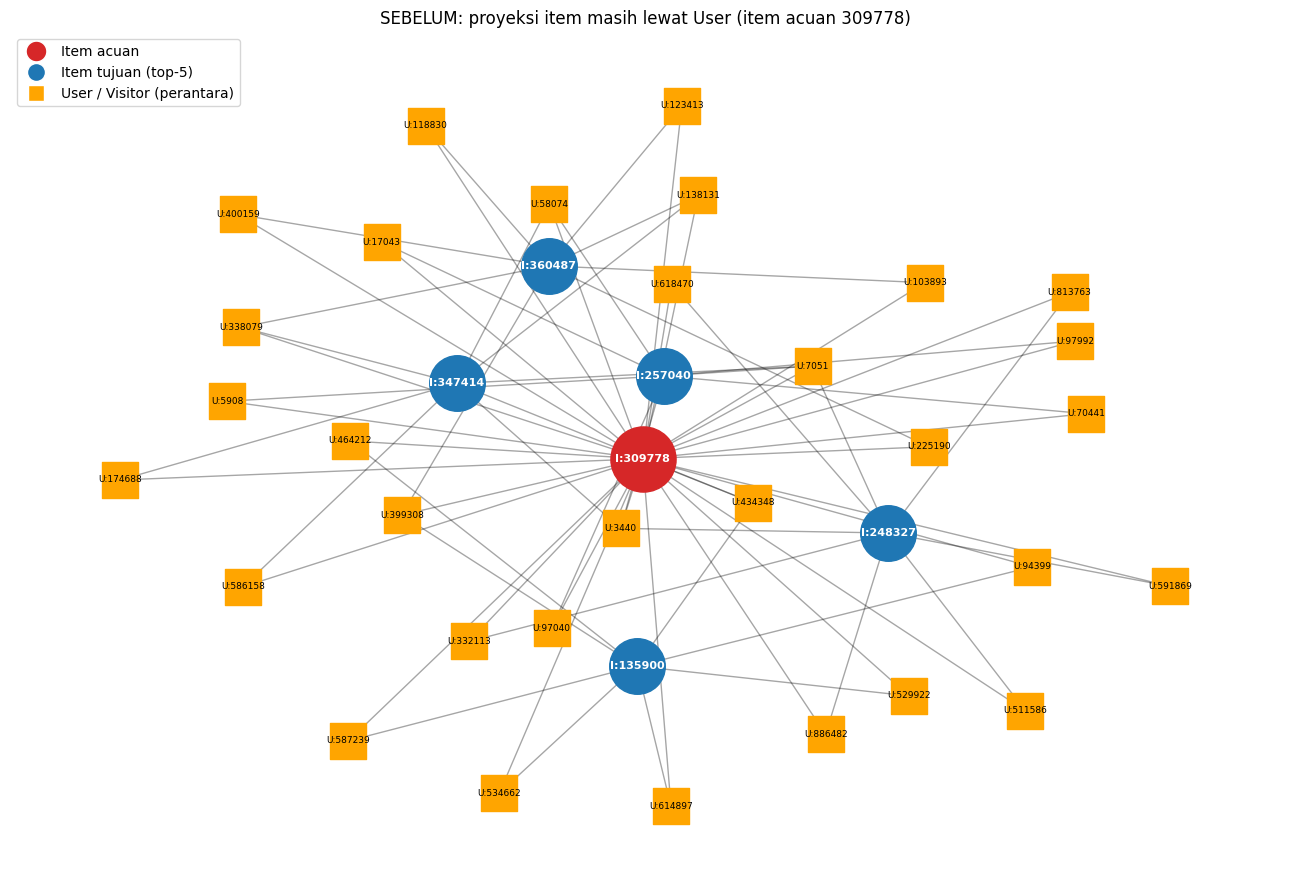

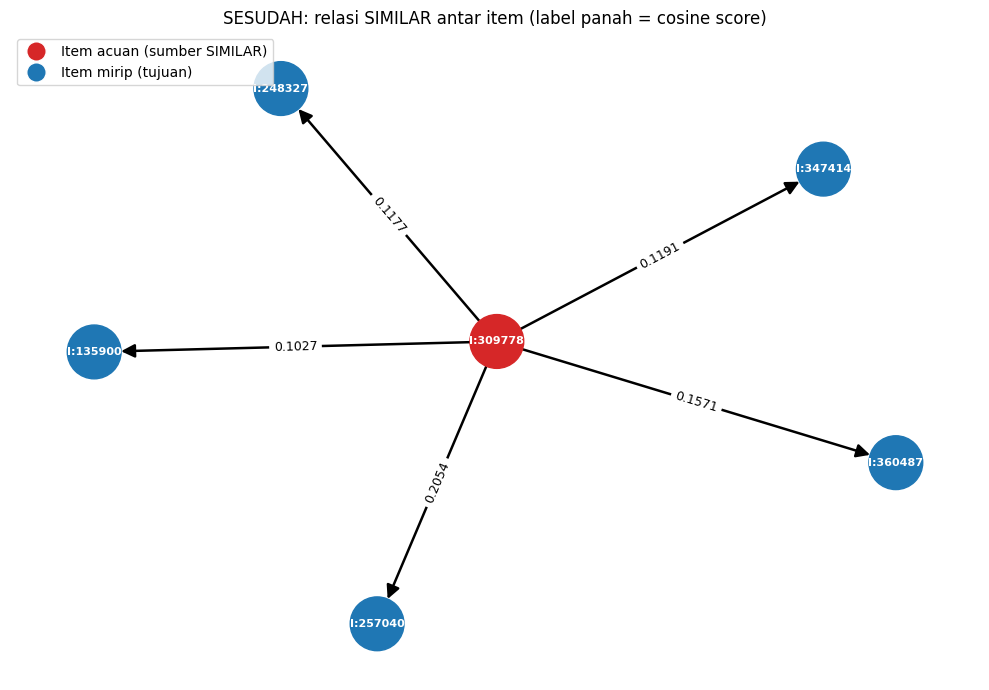

In [54]:
item_acuan  = int(df_7a["item_acuan"].iloc[0])
item_tujuan = [int(x) for x in df_7a["item_tujuan"]]
MAX_VISITOR = 8

q_sebelum = """
MATCH (a:Item {itemId: $acuan})<-[]-(v:Visitor)-[]->(b:Item)
WHERE b.itemId IN $tujuan
RETURN DISTINCT v.visitorId AS visitor, b.itemId AS tujuan
ORDER BY tujuan, visitor
"""
with driver.session(database=DATABASE) as session:
    df_sebelum = pd.DataFrame(session.run(q_sebelum, acuan=item_acuan, tujuan=item_tujuan).data())

df_plot = df_sebelum.groupby("tujuan", group_keys=False).head(MAX_VISITOR)

G1 = nx.Graph()
G1.add_node(("I", item_acuan))
for _, r in df_plot.iterrows():
    G1.add_edge(("U", int(r["visitor"])), ("I", item_acuan))
    G1.add_edge(("U", int(r["visitor"])), ("I", int(r["tujuan"])))

acuan_nodes  = [("I", item_acuan)]
tujuan_nodes = [n for n in G1 if n[0] == "I" and n != ("I", item_acuan)]
user_nodes   = [n for n in G1 if n[0] == "U"]

pos1 = nx.spring_layout(G1, seed=42, k=0.7)
plt.figure(figsize=(13, 9))
nx.draw_networkx_edges(G1, pos1, alpha=0.35)
nx.draw_networkx_nodes(G1, pos1, nodelist=acuan_nodes,  node_shape="o", node_color="tab:red",  node_size=2200)
nx.draw_networkx_nodes(G1, pos1, nodelist=tujuan_nodes, node_shape="o", node_color="tab:blue", node_size=1600)
nx.draw_networkx_nodes(G1, pos1, nodelist=user_nodes,   node_shape="s", node_color="orange",   node_size=700)
nx.draw_networkx_labels(G1, pos1, labels={n: f"I:{n[1]}" for n in acuan_nodes + tujuan_nodes},
                        font_size=8, font_color="white", font_weight="bold")
nx.draw_networkx_labels(G1, pos1, labels={n: f"U:{n[1]}" for n in user_nodes},
                        font_size=6.5, font_color="black")
plt.legend(handles=[
    Line2D([0],[0], marker="o", color="w", markerfacecolor="tab:red",  markersize=15, label="Item acuan"),
    Line2D([0],[0], marker="o", color="w", markerfacecolor="tab:blue", markersize=13, label="Item tujuan (top-5)"),
    Line2D([0],[0], marker="s", color="w", markerfacecolor="orange",   markersize=11, label="User / Visitor (perantara)"),
], loc="upper left")
plt.title(f"SEBELUM: proyeksi item masih lewat User (item acuan {item_acuan})")
plt.axis("off"); plt.tight_layout(); plt.show()

q_sesudah = """
MATCH (a:Item)-[s:SIMILAR]->(b:Item)
RETURN a.itemId AS item_a, b.itemId AS item_b, s.score AS score
"""
with driver.session(database=DATABASE) as session:
    df_sesudah = pd.DataFrame(session.run(q_sesudah).data())

G2 = nx.DiGraph()
for _, r in df_sesudah.iterrows():
    G2.add_edge(int(r["item_a"]), int(r["item_b"]), score=float(r["score"]))

sumber = {u for u, _ in G2.edges()}

pos2 = nx.spring_layout(G2, seed=42)
plt.figure(figsize=(10, 7))
nx.draw_networkx_nodes(G2, pos2, node_size=1500,
                       node_color=["tab:red" if n in sumber else "tab:blue" for n in G2])
nx.draw_networkx_edges(G2, pos2, arrows=True, arrowsize=20, width=1.8, node_size=1500)
nx.draw_networkx_labels(G2, pos2, labels={n: f"I:{n}" for n in G2},
                        font_size=8, font_color="white", font_weight="bold")
nx.draw_networkx_edge_labels(G2, pos2,
                             edge_labels={(u, v): d["score"] for u, v, d in G2.edges(data=True)},
                             font_size=9)
plt.legend(handles=[
    Line2D([0],[0], marker="o", color="w", markerfacecolor="tab:red",  markersize=14, label="Item acuan (sumber SIMILAR)"),
    Line2D([0],[0], marker="o", color="w", markerfacecolor="tab:blue", markersize=14, label="Item mirip (tujuan)"),
], loc="upper left")
plt.title("SESUDAH: relasi SIMILAR antar item (label panah = cosine score)")
plt.axis("off"); plt.tight_layout(); plt.show()

Setelah perhitungan similarity, hubungan antara item acuan 309778 dan kelima item lain tidak lagi melalui user, melainkan menjadi relasi langsung SIMILAR yang membawa skor cosine. Item 257040 paling mirip (0,2054), diikuti 360487 (0,1571), 347414 (0,1191), 248327 (0,1177), dan 135900 (0,1027). Skor yang relatif kecil mencerminkan data interaksi yang jarang dan efek item acuan yang sangat populer. Graf yang semula User-Item menjadi graf Item-Item berbobot yang dapat dipakai langsung untuk mencari tetangga terdekat (KNN) pada tahap rekomendasi.

# 2.2 Analytics

### Inisialisasi Parameter dan Memuat Dataset

Sel ini mengimpor pustaka yang diperlukan, menentukan konfigurasi konstanta dasar, memuat data interaksi user-item periode P1 (train) dan P2 (test), serta menampilkan ringkasan statistik dasar dari kedua dataset tersebut.

#### Langkah-Langkah Pemrosesan:

1. Pengimporan Pustaka: Mengimpor pustaka pandas, numpy, dan defaultdict yang digunakan untuk manipulasi dataframe serta operasi struktur data.
2. Konfigurasi Parameter Utama: Mengatur nilai SEED = 42 untuk menjaga konsistensi hasil acakan, K = 5 sebagai jumlah tetangga terdekat, dan N_IKLAN = 3 sebagai jumlah produk rekomendasi iklan.
3. Pemuatan Dataset P1 dan P2: Membaca file CSV events_p1_train.csv sebagai data latih dan events_p2_test.csv sebagai data uji ke dalam bentuk DataFrame.
4. Pemeriksaan Dimensi dan Entitas Unik: Menghitung dan mencetak dimensi dataset (jumlah baris dan kolom) serta total pengguna unik (visitorid) dan produk unik (itemid) pada masing-masing periode.

In [76]:
SEED = 42
K = 5
N_IKLAN = 3

p1 = pd.read_csv("data_filtered/events_p1_train.csv")
p2 = pd.read_csv("data_filtered/events_p2_test.csv")

print("P1:", p1.shape, "| user:", p1["visitorid"].nunique(), "| item:", p1["itemid"].nunique())
print("P2:", p2.shape, "| user:", p2["visitorid"].nunique(), "| item:", p2["itemid"].nunique())

P1: (630821, 5) | user: 326311 | item: 120903
P2: (201000, 5) | user: 116597 | item: 64505


Hasil tersebut menunjukkan bahwa dataset P1 memiliki skala yang lebih besar dengan 630.821 baris interaksi dari 326.311 pengguna dan 120.903 produk sebagai data latih, sedangkan dataset P2 berisi 201.000 baris interaksi dari 116.597 pengguna dan 64.505 produk yang digunakan sebagai data uji untuk evaluasi model.

### Seleksi Pengguna dan Pemilihan Target

Bagian kode ini bertugas menyaring daftar pengguna yang layak dijadikan bahan pengujian, lalu memilih satu pengguna secara acak untuk diuji. Pengguna yang dipilih harus aktif di periode awal dan melihat produk baru di periode berikutnya.

Langkah-Langkah Pemrosesan:

1. Menghapus Data Duplikat: Mengambil pasangan pengguna dan produk, lalu menghapus interaksi yang terulang agar datanya lebih bersih.
2. Menyaring Pengguna Aktif P1: Mencari pengguna yang minimal pernah melihat 5 produk berbeda pada periode pertama.
3. Mencari Produk Baru P2: Membandingkan data periode kedua dengan periode pertama untuk menemukan pengguna yang mengunjungi produk baru yang belum pernah mereka lihat sebelumnya.
4. Menentukan Daftar Kandidat: Mengambil pengguna yang memenuhi kedua syarat di atas, lalu mengurutkannya agar daftar kandidat tidak berubah-ubah.
5. Memilih Pengguna Target: Mengambil satu ID pengguna secara acak dari daftar kandidat memakai nilai SEED yang sudah dikunci.

In [77]:
pair1 = p1[["visitorid", "itemid"]].drop_duplicates()
pair2 = p2[["visitorid", "itemid"]].drop_duplicates()

n_item_p1 = pair1.groupby("visitorid")["itemid"].nunique()
ok_p1 = set(n_item_p1[n_item_p1 >= 5].index)

baru = pair2.merge(pair1, on=["visitorid", "itemid"], how="left", indicator=True)
baru = baru[baru["_merge"] == "left_only"]
ok_p2 = set(baru["visitorid"].unique())

kandidat = sorted(ok_p1 & ok_p2)
print("Jumlah kandidat user:", len(kandidat))

rng = np.random.default_rng(SEED)
user_id = int(rng.choice(kandidat))
print("User terpilih:", user_id)

Jumlah kandidat user: 421
User terpilih: 144241


# 1.a Skrip python dalam merekomendasikan KNN
Kode ini berfungsi untuk menyaring kandidat produk hasil KNN agar tidak merekomendasikan produk yang sudah pernah dilihat pengguna, lalu mencari produk-produk lain yang paling mirip dengan produk yang pernah dilihat oleh pengguna. Tingkat kemiripannya dihitung berdasarkan seberapa banyak pengunjung yang melihat kedua produk tersebut secara bersamaan di dalam database Neo4j.

In [78]:
q_riwayat = """
MATCH (v:Visitor {visitorId: $uid})-[r]->(i:Item)
RETURN i.itemId AS item, collect(DISTINCT type(r)) AS event
ORDER BY item
"""
q_knn = """
MATCH (t:Item {itemId: $item})<--(v1:Visitor)
WITH t, count(DISTINCT v1) AS target_users
MATCH (t)<--(v:Visitor)-->(o:Item)
WHERE o <> t
WITH t, target_users, o, count(DISTINCT v) AS shared_visitors
MATCH (o)<--(v2:Visitor)
WITH t, o, shared_visitors, target_users, count(DISTINCT v2) AS other_users
RETURN t.itemId AS item_asal,
       o.itemId AS item_tetangga,
       shared_visitors,
       round(toFloat(shared_visitors) / sqrt(toFloat(target_users) * toFloat(other_users)), 4) AS cosine
ORDER BY cosine DESC, shared_visitors DESC, item_tetangga ASC
LIMIT $k
"""
with driver.session(database=DATABASE) as session:
    df_riwayat = pd.DataFrame(session.run(q_riwayat, uid=user_id).data())
 
seen_items = [int(x) for x in df_riwayat["item"]]
baris = []

with driver.session(database=DATABASE) as session:
    for it in seen_items:
        baris += session.run(q_knn, item=it, k=K).data()

df_knn = pd.DataFrame(baris)
print(f"Total pasangan (item_asal -> tetangga): {len(df_knn)}")
print(df_knn.to_string(index=False))

Total pasangan (item_asal -> tetangga): 24
 item_asal  item_tetangga  shared_visitors  cosine
     84593         423748                6  0.1667
     84593         344469                5  0.1604
     84593          97139               10  0.1375
     84593         116886                4  0.1283
     84593         221501                5  0.1076
    174409         218817                5  0.1627
    174409           4020                1  0.1491
    174409          19531                1  0.1491
    174409          47508                1  0.1491
    174409          70894                1  0.1491
    197901         387373                1  0.0615
    197901         257635                1  0.0503
    197901         174409                1  0.0449
    197901          84593                1  0.0290
    257635            697                1  0.1667
    257635           4115                1  0.1667
    257635           8012                1  0.1667
    257635          44297              

# 1.b Menulisakan 3 item yang diiklankan untuk k = 5
Mengambil sejumlah ID produk teratas dari daftar rekomendasi sesuai batas jumlah iklan yang ditentukan, sehingga menghasilkan output berupa pesan teks yang menampilkan daftar ID produk pilihan yang siap diiklankan kepada target pengguna.

In [79]:
skor = defaultdict(float)
sumber = defaultdict(list)

for _, r in df_knn.iterrows():
    kandidat_item = int(r["item_tetangga"])
    if kandidat_item in seen_items:
        continue
    skor[kandidat_item] += float(r["cosine"])     
    sumber[kandidat_item].append(int(r["item_asal"]))

ranking = sorted(skor.items(), key=lambda x: (-x[1], x[0]))  
rekomendasi_top5 = ranking[:K]

df_rek = pd.DataFrame([
    {"peringkat": i + 1, "item": it, "skor_total": round(s, 4), "muncul_dari": len(sumber[it])}
    for i, (it, s) in enumerate(rekomendasi_top5)
])
print(f"Jumlah kandidat: {len(ranking)}")
print(df_rek.to_string(index=False))

Jumlah kandidat: 20
 peringkat   item  skor_total  muncul_dari
         1  67787      0.2041            1
         2 100589      0.2041            1
         3 133700      0.2041            1
         4 140360      0.2041            1
         5 225706      0.2041            1


Hasil tersebut menunjukkan bahwa dari total 20 kandidat produk yang teridentifikasi, dipilih 5 produk teratas sebagai rekomendasi utama. Kelima produk ini (67787, 100589, 133700, 140360, dan 225706) memiliki skor kemiripan total yang identik sebesar 0,2041 dan masing-masing hanya dipicu oleh 1 produk asal dari riwayat pengguna.

In [81]:
rekomendasi_top3 = ranking[:N_IKLAN]

df_rek3 = pd.DataFrame([
    {"peringkat": i + 1, "item": it, "skor_total": round(s, 4), "muncul_dari": len(sumber[it])}
    for i, (it, s) in enumerate(rekomendasi_top3)
])
print(df_rek3.to_string(index=False))

 peringkat   item  skor_total  muncul_dari
         1  67787      0.2041            1
         2 100589      0.2041            1
         3 133700      0.2041            1


Menunjukkan bahwa top 3 item yaitu 67787, 100589, dan 133700

# 2.a dan 2.b
Kode ini berfungsi untuk menghitung nilai metrik evaluasi Hit@5 dan NDCG@5 dengan cara membandingkan daftar 5 produk rekomendasi terhadap produk relevan di periode P2, sehingga menghasilkan output berupa tampilan angka skor keberhasilan rekomendasi (Hit@5) dan akurasi urutan peringkat rekomendasi (NDCG@5).

In [82]:
p2_user = p2[p2["visitorid"] == user_id]
items_p2 = set(int(x) for x in p2_user["itemid"].unique())

relevan = items_p2 - set(seen_items)

print("Event user di P2:", p2_user["event"].value_counts().to_dict())
print(f"Item unik di P2: {len(items_p2)} | relevan (ground truth): {len(relevan)}")
print("Relevan:", sorted(relevan))

Event user di P2: {'view': 1}
Item unik di P2: 1 | relevan (ground truth): 1
Relevan: [172872]


In [83]:
rek_list = [it for it, _ in rekomendasi_top5]
rel_vec = [1 if it in relevan else 0 for it in rek_list]

hit_at_5 = 1 if sum(rel_vec) > 0 else 0

dcg = sum(rel / math.log2(pos + 2) for pos, rel in enumerate(rel_vec))
idcg = sum(1 / math.log2(pos + 2) for pos in range(min(K, len(relevan))))
ndcg_at_5 = dcg / idcg if idcg > 0 else 0.0

print(f"(a) Hit@5  = {hit_at_5:.4f}")
print(f"(b) NDCG@5 = {ndcg_at_5:.4f}")

(a) Hit@5  = 0.0000
(b) NDCG@5 = 0.0000


Perolehan skor Hit@5 dan NDCG@5 bernilai 0.0000 terjadi karena produk yang direkomendasikan sistem gagal mencocokkan interaksi pengguna pada periode data uji. Hasil skor nol ini berkaitan langsung dengan karakteristik matriks yang memiliki tingkat kekosongan sebesar 99,9987% dan rata-rata interaksi yang hanya 4,05 pengguna per produk. Kondisi data yang sangat renggang dapat dilihat pada grafik proyeksi item, di mana keterhubungan antarproduk hanya menumpuk padat pada sekelompok kecil produk populer di bagian pusat, sedangkan sebagian besar produk lainnya berada di area pinggiran dengan hubungan yang sangat tipis atau terisolasi. Akibatnya, ketika sistem mencari produk tetangga menggunakan KNN untuk item yang tidak berada di klaster pusat, algoritma kesulitan menemukan kesamaan pola yang kuat sehingga rekomendasi yang dihasilkan menjadi kurang tepat dan berakhir pada skor evaluasi nol.